# Análisis de errores por segmento de precio
### AVM · Distrito Centro (Rosario)

Métricas por partición (3 familias) y error por segmento del **LightGBM final** (notebook 04, vía `modelo_final.py`).


In [1]:
from pathlib import Path
import sys, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
ROOT=Path.cwd()
while not (ROOT/"data"/"processed").exists() and ROOT!=ROOT.parent: ROOT=ROOT.parent
sys.path.insert(0, str(ROOT/"scripts"/"modeling")); import modelo_final as mf   # modelo final de PI1 (notebook 04)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.dpi":120})
TAB=ROOT/"reports"/"tables"/"modelado"; FIG=ROOT/"reports"/"figures"/"resultados"
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
df=mf.cargar_matriz(ROOT); yv=pd.to_numeric(df["eda_precio_usd"],errors="coerce").values.astype(float)
ytil=mf.target_log(df); groups=df["building_cluster_id"].values; cols=mf.columnas_S4(df); X=df[cols]


## 1. Métricas por partición


In [2]:
modelos={"Hedónico":("hed",True),"Random Forest":("rf",False),"LightGBM":("lgb",False)}
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
CAT=[c for c in cols if c in mf.CAT]; BIN=[c for c in cols if c in mf._binarias(df)]; NUM=[c for c in cols if c not in CAT and c not in BIN]
def prep(scale): return ColumnTransformer([("num",Pipeline([("i",SimpleImputer(strategy="median"))]+([("s",StandardScaler())] if scale else [])),NUM),
  ("bin",SimpleImputer(strategy="most_frequent"),BIN),("cat",Pipeline([("i",SimpleImputer(strategy="most_frequent")),("o",OneHotEncoder(handle_unknown="ignore",min_frequency=10,sparse_output=False))]),CAT)])
def build(tag):
    if tag=="hed": return Pipeline([("p",prep(True)),("m",LinearRegression())])
    if tag=="rf":  return Pipeline([("p",prep(False)),("m",RandomForestRegressor(n_estimators=600,max_depth=16,random_state=0,n_jobs=-1))])
    return mf.construir_modelo_final(cols,df)   # LightGBM final
gkf=GroupKFold(5); filas=[]; oof_lgb=np.zeros(len(yv))
for nombre,(tag,_) in modelos.items():
    for k,(tr,va) in enumerate(gkf.split(X,ytil,groups),1):
        pred=build(tag).fit(X.iloc[tr],ytil[tr]).predict(X.iloc[va])
        filas.append({"modelo":nombre,"fold":k,"R2_log":round(r2_score(ytil[va],pred),4),"RMSE_USD":round(np.sqrt(mean_squared_error(yv[va],np.expm1(pred))))})
        if nombre=="LightGBM": oof_lgb[va]=pred
fold_tab=pd.DataFrame(filas); fold_tab.to_csv(TAB/"metricas_por_fold_s4.csv",index=False)
display(fold_tab.groupby("modelo").agg(R2_medio=("R2_log","mean"),R2_sd=("R2_log","std"),RMSE_medio=("RMSE_USD","mean")).round(3))


,R2_medio,R2_sd,RMSE_medio
modelo,,,
Hedónico,0.864,0.009,64790.2
LightGBM,0.902,0.008,39594.8
Random Forest,0.881,0.010,42958.2


## 2. Error del LightGBM final por segmento de precio (OOF)


,segmento,n,MAE_USD,MAPE,sesgo_medio_USD
0,< 80.000,1723,9981,18.7,4631
1,80.000–120.000,751,15618,15.8,147
2,120.000–180.000,917,22757,15.1,-3473
3,180.000–300.000,905,35192,15.1,-4541
4,> 300.000,469,68042,15.6,-47498


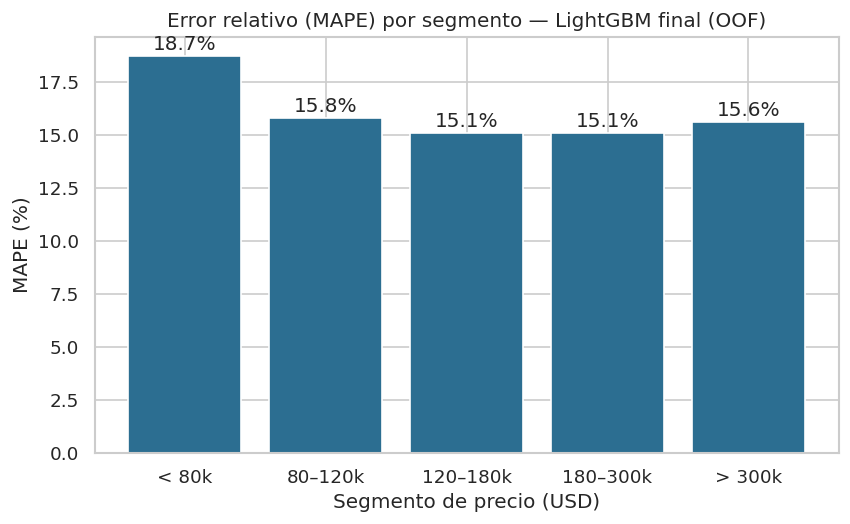

R2 OOF LightGBM: 0.902


In [3]:
pred_usd=np.expm1(oof_lgb)
seg=pd.cut(yv,[0,80000,120000,180000,300000,np.inf],labels=["< 80.000","80.000–120.000","120.000–180.000","180.000–300.000","> 300.000"])
rows=[]
for s in seg.categories:
    m=seg==s; rows.append({"segmento":s,"n":int(m.sum()),"MAE_USD":round(mean_absolute_error(yv[m],pred_usd[m])),"MAPE":round(np.mean(np.abs((yv[m]-pred_usd[m])/yv[m]))*100,1),"sesgo_medio_USD":round(np.mean(pred_usd[m]-yv[m]))})
segt=pd.DataFrame(rows); segt.to_csv(TAB/"error_por_segmento.csv",index=False); display(segt)
fig,ax=plt.subplots(figsize=(8,4.5)); ax.bar(range(len(segt)),segt["MAPE"],color="#2c6e91"); ax.set_xticks(range(len(segt))); ax.set_xticklabels(["< 80k","80–120k","120–180k","180–300k","> 300k"])
for i,v in enumerate(segt["MAPE"]): ax.text(i,v+0.3,f"{v:.1f}%",ha="center")
ax.set(ylabel="MAPE (%)",xlabel="Segmento de precio (USD)",title="Error relativo (MAPE) por segmento — LightGBM final (OOF)")
fig.savefig(FIG/"r6_error_por_segmento.png",bbox_inches="tight"); plt.show(); print("R2 OOF LightGBM:",round(r2_score(ytil,oof_lgb),3))
